# Classification in Heart Disease

## Part 1: Problem Understanding
Each row is one patient, and the response is yes or no. There are 164 No and 139 Yes, so the classes are balanced.

A false positive is a healthy patient flagged as sick. A false negative is a sick patient who is missed, which is worse.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve

heart = pd.read_csv("Heart.csv", index_col=0)
print(heart.shape)
print(heart["AHD"].value_counts())

(303, 14)
AHD
No     164
Yes    139
Name: count, dtype: int64


## Part 2: Data Preparation
Ca and Thal have some missing values, so I dropped those rows and kept 297 patients. I turned the text columns into 0/1 columns, split the data 75/25, and scaled it using only the training data.

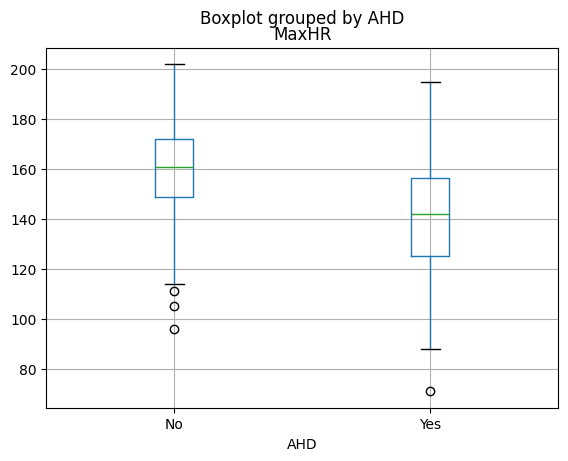

(297, 14)


In [3]:
heart.boxplot("MaxHR", by="AHD")
plt.show()

heart = heart.dropna()
print(heart.shape)

y = heart["AHD"].map({"No": 0, "Yes": 1})
x = pd.get_dummies(heart.drop(columns="AHD"), drop_first=True, dtype=int)

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.25, random_state=42, stratify=y)

scaler = StandardScaler()
x_train_s = scaler.fit_transform(x_train)
x_test_s = scaler.transform(x_test)

## Part 3: Build and Compare Classifiers
I fit the Logistic Regression, LDA, QDA, and KNN. For KNN I tried K from 1 to 30 and picked K = 16 because it scored the best.

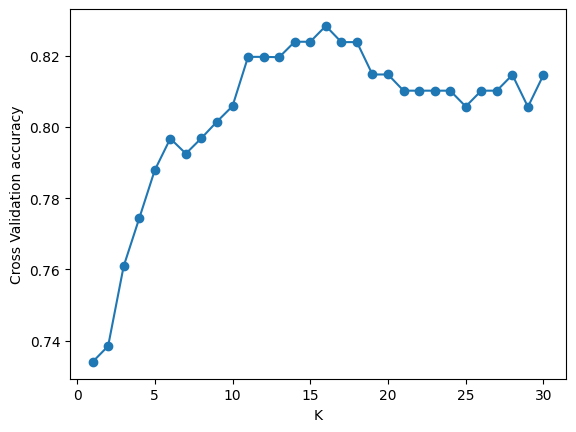

Best K: 16


In [10]:
logreg = LogisticRegression(max_iter=1000).fit(x_train_s, y_train)
lda = LinearDiscriminantAnalysis().fit(x_train_s, y_train)
qda = QuadraticDiscriminantAnalysis().fit(x_train_s, y_train)

k_values = range(1, 31)
cv_scores = []
for k in k_values:
    knn_k = KNeighborsClassifier(n_neighbors=k)
    cv_scores.append(cross_val_score(knn_k, x_train_s, y_train, cv=5).mean())

plt.plot(k_values, cv_scores, marker="o")
plt.xlabel("K")
plt.ylabel("Cross Validation accuracy")
plt.show()

best_k = list(k_values)[np.argmax(cv_scores)]
print("Best K:", best_k)
knn = KNeighborsClassifier(n_neighbors=best_k).fit(x_train_s, y_train)

## Part 4: Confusion Matrices
I used a threshold of 0.40 instead of 0.50. Missing a sick patient is worse than having a false alarm, so a lower threshold catches more sick patients.

In [9]:
models = {"Logistic Regression": logreg, "LDA": lda, "QDA": qda, "KNN": knn}
rows = []

for name, model in models.items():
    prob = model.predict_proba(x_test_s)[:, 1]
    pred = (prob >= 0.40).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    print(name)
    print(confusion_matrix(y_test, pred))
    rows.append([name, accuracy_score(y_test, pred), precision_score(y_test, pred), recall_score(y_test, pred), tn / (tn + fp), f1_score(y_test, pred), roc_auc_score(y_test, prob)])

results = pd.DataFrame(rows, columns=["Model", "Accuracy", "Precision", "Recall", "Specificity", "F1", "ROC AUC"]).round(3)
results

Logistic Regression
[[34  6]
 [ 3 32]]
LDA
[[35  5]
 [ 4 31]]
QDA
[[32  8]
 [ 6 29]]
KNN
[[32  8]
 [ 4 31]]


,Model,Accuracy,Precision,Recall,Specificity,F1,ROC AUC
0,Logistic Regression,0.880,0.842,0.914,0.850,0.877,0.936
1,LDA,0.880,0.861,0.886,0.875,0.873,0.934
2,QDA,0.813,0.784,0.829,0.800,0.806,0.914
3,KNN,0.840,0.795,0.886,0.800,0.838,0.936


## Part 5: Metrics Reflection
Recall is the most informative metric because it shows how many sick patients were caught. Specificity can also help, since accuracy alone can hide missed patients.

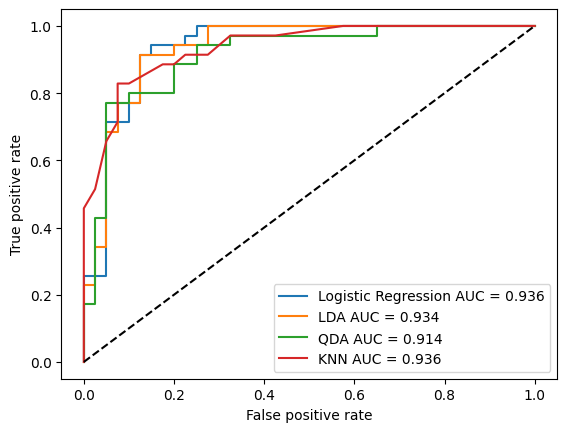

In [8]:
for name, model in models.items():
    prob = model.predict_proba(x_test_s)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label=name + " AUC = " + str(round(roc_auc_score(y_test, prob), 3)) + "")

plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.legend()
plt.show()

## Part 6: ROC Curve and AUC
The ROC curve shows how well each model separates sick paitents and healthy patients, and AUC is the area under it. Logistic Regression and KNN tie for the best AUC at 0.936, and QDA is lowest at 0.914.

## Part 7: Final Analysis
I would use Logistic Regression because it has the best recall, only missed 3 patients, and the top AUC. A limitation of this analysis is that the dataset is small, so I would want more patients from other hospitals.